In [19]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تحميل البيانات (تأكد من مسار الملف في Kaggle)
df = pd.read_csv('/kaggle/input/datasets/yazanpc/mobile-price-classification/train.csv')

X = df.drop('price_range', axis=1).values
y = df['price_range'].values  # الفئات: 0, 1, 2, 3

# 2. تقسيم البيانات وتوحيد القياس (ضروري جداً للـ RBF والـ Optimizers)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# 3. دالة حساب RBF Kernel من الصفر
def rbf_kernel(X1, X2, gamma=0.05):
  # حساب المسافة الإقليدية المربعة بين كل نقطتين
  sq_dists = (
      np.sum(X1**2, axis=1).reshape(-1, 1)
      + np.sum(X2**2, axis=1)
      - 2 * np.dot(X1, X2.T)
  )
  return np.exp(-gamma * sq_dists)


# تحويل البيانات إلى فضاء الـ Kernel
K_train = rbf_kernel(X_train, X_train, gamma=0.05)
K_test = rbf_kernel(X_test, X_train, gamma=0.05)


In [20]:
class KernelSVM_GD:

  def __init__(self, lr=0.001, C=1.0, epochs=200):
    self.lr = lr
    self.C = C
    self.epochs = epochs

  def fit(self, K, y):
    n_samples = K.shape[0]
    self.classes = np.unique(y)
    self.alpha = np.zeros((len(self.classes), n_samples))
    self.b = np.zeros(len(self.classes))
    self.losses = []

    for epoch in range(self.epochs):
      epoch_loss = 0
      for idx, c in enumerate(self.classes):
        y_binary = np.where(y == c, 1, -1)
        scores = np.dot(K, self.alpha[idx]) + self.b[idx]
        margins = y_binary * scores

        # حساب Hinge Loss + Regularization
        hinge = np.maximum(0, 1 - margins)
        loss = 0.5 * np.dot(self.alpha[idx], np.dot(K, self.alpha[idx])) + (
            self.C / n_samples
        ) * np.sum(hinge)
        epoch_loss += loss

        # حساب المشتقات (Gradients) لكامل البيانات دفعة واحدة
        misclassified = (margins < 1).astype(float)
        grad_alpha = np.dot(K, self.alpha[idx]) - (self.C / n_samples) * np.dot(
            K.T, misclassified * y_binary
        )
        grad_b = -(self.C / n_samples) * np.sum(misclassified * y_binary)

        # تحديث الأوزان
        self.alpha[idx] -= self.lr * grad_alpha
        self.b[idx] -= self.lr * grad_b

      self.losses.append(epoch_loss / len(self.classes))

  def predict(self, K_test):
    scores = np.dot(K_test, self.alpha.T) + self.b
    return self.classes[np.argmax(scores, axis=1)]


model = KernelSVM_GD(lr=0.001, C=10.0, epochs=200)


Training Time: 1.3580 seconds
Test Accuracy: 47.50%

Classification Report (Precision, Recall, F1-Score):
                    precision    recall  f1-score   support

      Low Cost (0)       1.00      0.07      0.13       100
   Medium Cost (1)       0.40      0.61      0.49       100
     High Cost (2)       0.40      0.22      0.28       100
Very High Cost (3)       0.53      1.00      0.70       100

          accuracy                           0.47       400
         macro avg       0.58      0.47      0.40       400
      weighted avg       0.58      0.47      0.40       400



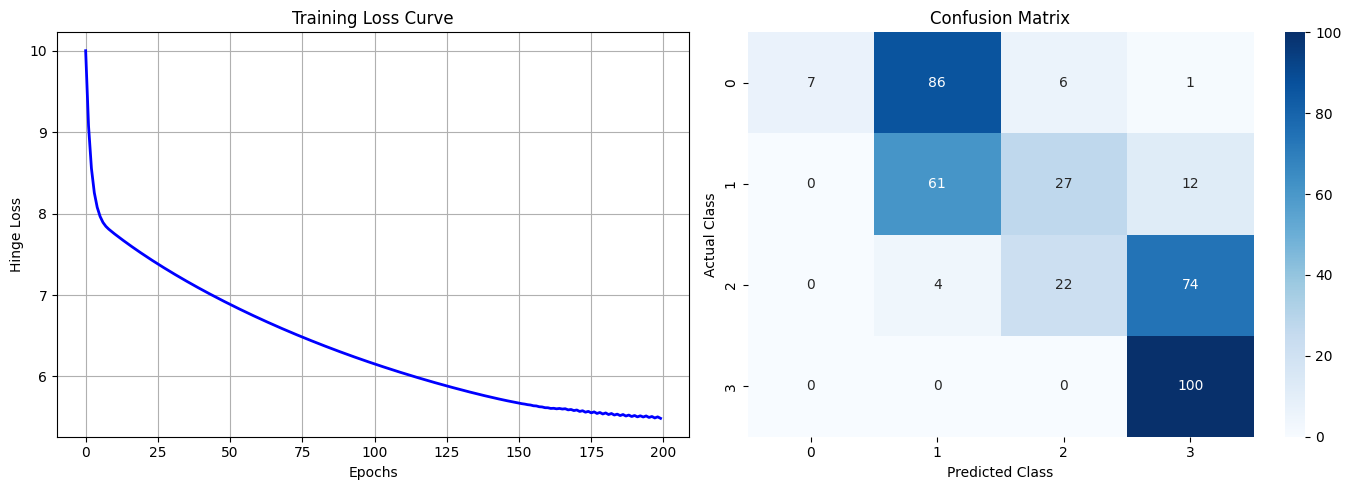

In [21]:
# تدريب النموذج وحساب الوقت
start_time = time.time()
model.fit(K_train, y_train)
training_time = time.time() - start_time

# التنبؤ على بيانات الاختبار
y_pred = model.predict(K_test)

# 1. طباعة النتائج والنسب
print(f"Training Time: {training_time:.4f} seconds")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report (Precision, Recall, F1-Score):")
print(classification_report(y_test, y_pred, target_names=['Low Cost (0)', 'Medium Cost (1)', 'High Cost (2)', 'Very High Cost (3)']))

# 2. رسم منحنى الخسارة (Loss Curve) ومصفوفة الارتباك (Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# رسم Loss
axes[0].plot(model.losses, color='blue', linewidth=2)
axes[0].set_title('Training Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Hinge Loss')
axes[0].grid(True)

# رسم Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['0', '1', '2', '3'], yticklabels=['0', '1', '2', '3'])
axes[1].set_title('Confusion Matrix')
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('Actual Class')

plt.tight_layout()
plt.show()
